# Evaluación de los modelos guardados

In [1]:
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import classification_report

from utilidades import (ConvNet, crear_dataloaders, evaluar, dibujar_matriz_confusion, device, MEDIA_IMAGENET,
                        DESVIACION_IMAGENET)

print(f'Usando dispositivo: {device}')

Usando dispositivo: cuda


## Modelo final: C8

In [2]:
configuracion_c8 = {
    'tam_imagen': 128,
    'tam_lote': 64,
    'filtros': (16, 32, 64),
    'neuronas_fc': (256, 128),
    'activacion': nn.LeakyReLU,
    'p_dropout': 0.5,
}

_, _, dataloader_test, clases = crear_dataloaders('datos', configuracion_c8['tam_imagen'],
                                                  configuracion_c8['tam_lote'])

modelo_c8 = ConvNet(len(clases), configuracion_c8['tam_imagen'], configuracion_c8['filtros'],
                    configuracion_c8['neuronas_fc'], configuracion_c8['activacion'],
                    configuracion_c8['p_dropout']).to(device)
modelo_c8.load_state_dict(torch.load('modelos/Final-C8.pth', map_location=device))

y_real, y_pred, perdida_test, acc_test = evaluar(modelo_c8, dataloader_test)

print(f'Test Loss: {perdida_test:.4f} | Test Acc: {acc_test:.4f}')
print(f'Imágenes mal clasificadas: {(y_real != y_pred).sum()} de {len(y_real)}')
print(classification_report(y_real, y_pred, target_names=clases, digits=4))

Test Loss: 0.0155 | Test Acc: 0.9969
Imágenes mal clasificadas: 11 de 3570
              precision    recall  f1-score   support

     cushion     0.9922    1.0000    0.9961       510
     emerald     0.9980    0.9961    0.9971       510
       heart     1.0000    0.9980    0.9990       510
        oval     1.0000    1.0000    1.0000       510
        pear     0.9980    0.9941    0.9961       510
    princess     1.0000    0.9902    0.9951       510
       round     0.9903    1.0000    0.9951       510

    accuracy                         0.9969      3570
   macro avg     0.9969    0.9969    0.9969      3570
weighted avg     0.9969    0.9969    0.9969      3570



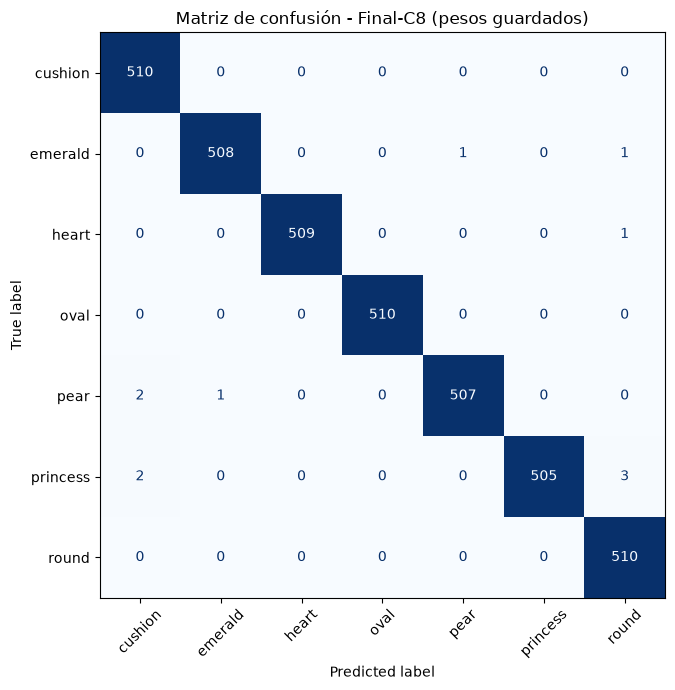

In [3]:
dibujar_matriz_confusion(y_real, y_pred, clases, 'Final-C8 (pesos guardados)')

## Transferencia de conocimiento: ResNet18 con ajuste fino

In [4]:
_, _, dataloader_test_tl, clases_tl = crear_dataloaders('datos', 224, 32, media=MEDIA_IMAGENET,
                                                        desviacion=DESVIACION_IMAGENET)

resnet = models.resnet18(weights=None)
resnet.fc = nn.Linear(resnet.fc.in_features, len(clases_tl))
resnet.load_state_dict(torch.load('modelos/TL-ResNet18-ajuste-fino.pth', map_location=device))
resnet = resnet.to(device)

y_real_tl, y_pred_tl, perdida_test_tl, acc_test_tl = evaluar(resnet, dataloader_test_tl)

print(f'Test Loss: {perdida_test_tl:.4f} | Test Acc: {acc_test_tl:.4f}')
print(f'Imágenes mal clasificadas: {(y_real_tl != y_pred_tl).sum()} de {len(y_real_tl)}')
print(classification_report(y_real_tl, y_pred_tl, target_names=clases_tl, digits=4))

Test Loss: 0.0100 | Test Acc: 0.9994
Imágenes mal clasificadas: 2 de 3570
              precision    recall  f1-score   support

     cushion     1.0000    1.0000    1.0000       510
     emerald     0.9980    1.0000    0.9990       510
       heart     1.0000    0.9980    0.9990       510
        oval     1.0000    1.0000    1.0000       510
        pear     1.0000    0.9980    0.9990       510
    princess     1.0000    1.0000    1.0000       510
       round     0.9980    1.0000    0.9990       510

    accuracy                         0.9994      3570
   macro avg     0.9994    0.9994    0.9994      3570
weighted avg     0.9994    0.9994    0.9994      3570



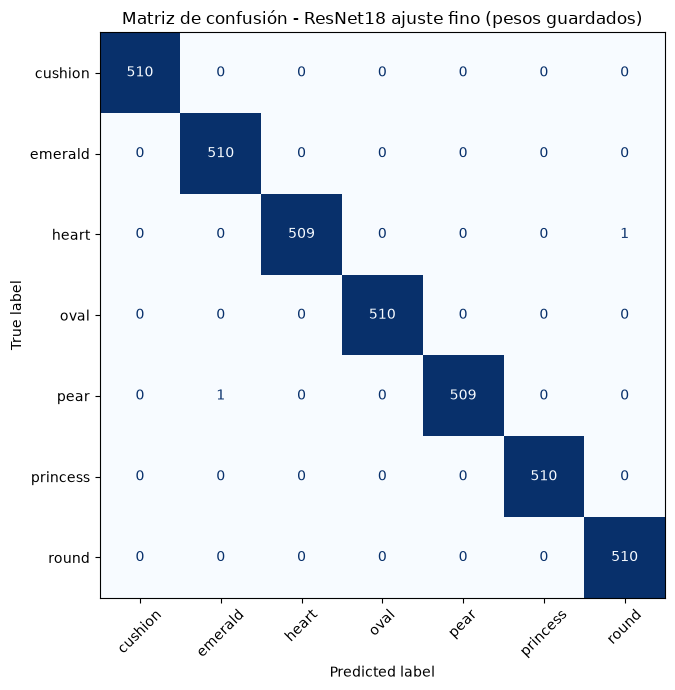

In [5]:
dibujar_matriz_confusion(y_real_tl, y_pred_tl, clases_tl, 'ResNet18 ajuste fino (pesos guardados)')